# 3D Printer
The printer head is moved by two motors (left and right). Each motor has a mechanical part (angle, speed) and an electrical part (current).

States:
- $x_1$: angle of left motor, $x_2$: speed of left motor, $x_3$: current of left motor
- $x_4$: angle of right motor, $x_5$: speed of right motor, $x_6$: current of right motor

$$\begin{bmatrix} \dot{x}_1 \\ \dot{x}_2 \\ \dot{x}_3 \\ \dot{x}_4 \\ \dot{x}_5 \\ \dot{x}_6 \end{bmatrix} = \begin{bmatrix} x_2 \\ \frac{K_m x_3 - \left[ \frac{r_m^2}{4}(\mu_{l,x} + \mu_{l,y}) + \mu_r \right] x_2 - \left[ \frac{r_m^2}{4}(\mu_{l,x} - \mu_{l,y}) \right] x_5}{\frac{1}{2}m r_m^2 + J_m} \\ \frac{1}{L_m} (u_{m,l} - R_m x_3 - K_m x_2) \\ x_5 \\ \frac{K_m x_6 - \left[ \frac{r_m^2}{4}(\mu_{l,x} - \mu_{l,y}) \right] x_2 - \left[ \frac{r_m^2}{4}(\mu_{l,x} + \mu_{l,y}) + \mu_r \right] x_5}{\frac{1}{2}m r_m^2 + J_m} \\ \frac{1}{L_m} (u_{m,r} - R_m x_6 - K_m x_5) \end{bmatrix}$$

In [5]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from math import pi

## Parameters

In [6]:
###DONT USE THESE PARAMETERS IN THE SIMULATION, THEY ARE JUST FOR REFERENCE###



K_m  = 0.07    # motor constant (Nm/A)
r_m  = 0.011   # motor radius (m)
m    = 0.06    # tool head mass (kg)
J_m  = 8e-6    # motor inertia (kg m^2)
mu_lx = 0.002  # bearing friction linear x-direction (Ns/m)
mu_ly = 0.001  # bearing friction linear y-direction (Ns/m)
mu_r = 0.003   # bearing friction rolling (Ns/m)
L_m  = 0.01    # motor inductance (H)
R_m  = 90.0    # motor resistance (Ohm)

u_ml = 12.0    # voltage left motor (V) - not given, chosen
u_mr = 6.0     # voltage right motor (V) - not given, chosen


a = r_m**2 / 4 * (mu_lx + mu_ly) + mu_r
b = r_m**2 / 4 * (mu_lx - mu_ly)
J = 0.5 * m * r_m**2 + J_m

## System equations

In [7]:
def f(t, x):
    x1 = x[0]
    x2 = x[1]
    x3 = x[2]
    x4 = x[3]
    x5 = x[4]
    x6 = x[5]


    dx1 = x2
    dx2 = (K_m * x3 - a * x2 - b * x5) / J
    dx3 = (u_ml - R_m * x3 - K_m * x2) / L_m
    dx4 = x5
    dx5 = (K_m * x6 - b * x2 - a * x5) / J
    dx6 = (u_mr - R_m * x6 - K_m * x5) / L_m

    return [dx1, dx2, dx3, dx4, dx5, dx6]

## Simulate

In [8]:
x0 = [0, 0, 0, 0, 0, 0]
t_span = (0, 1)
t_eval = np.linspace(0, 1, 1000)

sol = solve_ivp(f, t_span, x0, t_eval=t_eval)


t = sol.t
x = sol.y

## Plot

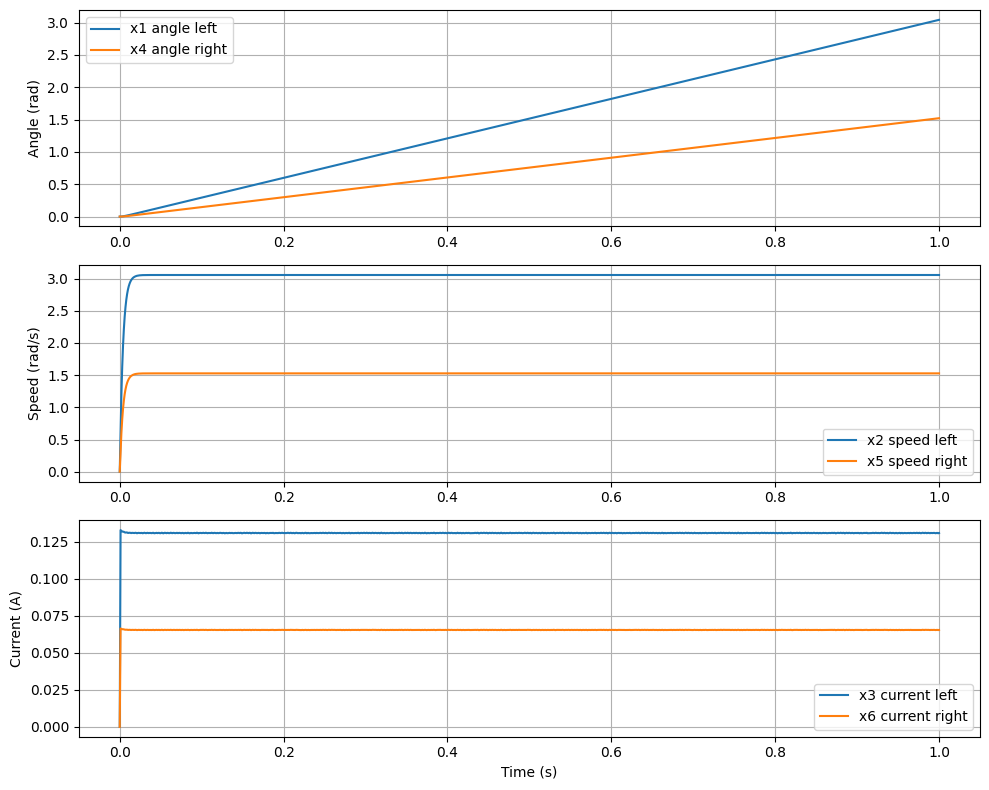

In [9]:
plt.figure(figsize=(10, 8))

plt.subplot(3, 1, 1)
plt.plot(t, x[0], label='x1 angle left')
plt.plot(t, x[3], label='x4 angle right')
plt.ylabel('Angle (rad)')
plt.legend()
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, x[1], label='x2 speed left')
plt.plot(t, x[4], label='x5 speed right')
plt.ylabel('Speed (rad/s)')
plt.legend()
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, x[2], label='x3 current left')
plt.plot(t, x[5], label='x6 current right')
plt.ylabel('Current (A)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Tool head trajectory
$$x = \frac{r_m}{2}(\theta_l + \theta_r), \quad y = \frac{r_m}{2}(\theta_l - \theta_r)$$
$$\dot x = \frac{r_m}{2}(\dot\theta_l + \dot\theta_r), \quad \dot y = \frac{r_m}{2}(\dot\theta_l - \dot\theta_r)$$

In [10]:
theta_l = x[0]
theta_l_dot = x[1]
theta_r = x[3]
theta_r_dot = x[4]

pos_x = r_m * (theta_l + theta_r) / 2
pos_y = r_m * (theta_l - theta_r) / 2
vel_x = r_m * (theta_l_dot + theta_r_dot) / 2
vel_y = r_m * (theta_l_dot - theta_r_dot) / 2

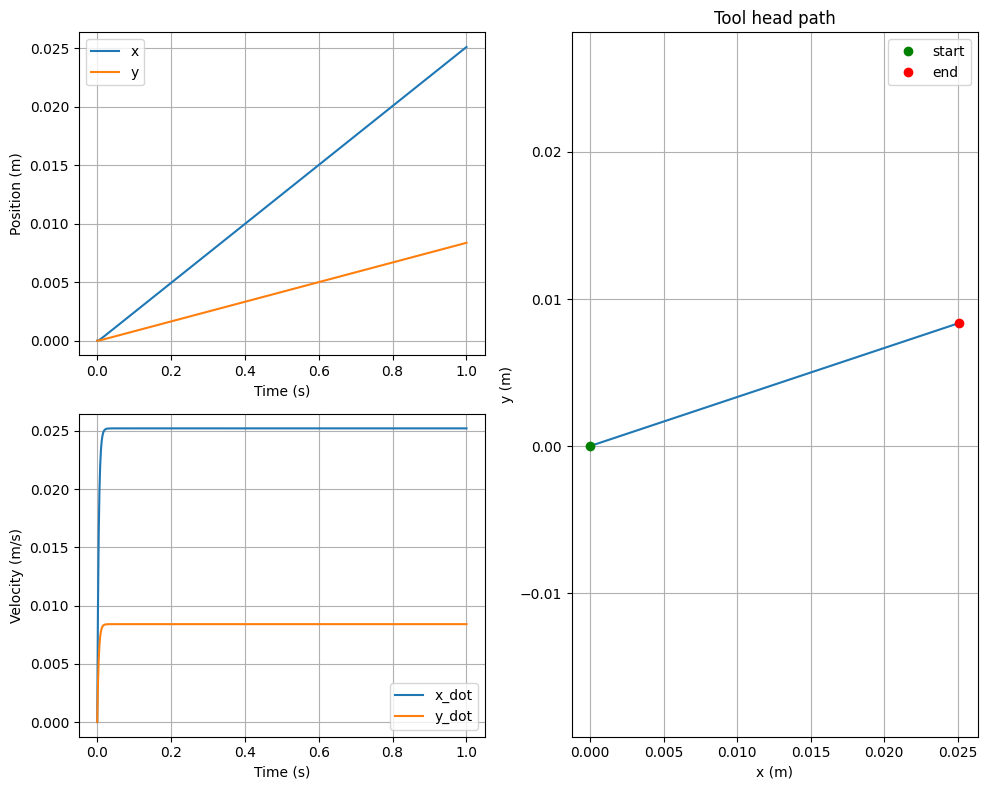

In [11]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.plot(t, pos_x, label='x')
plt.plot(t, pos_y, label='y')
plt.ylabel('Position (m)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid()

plt.subplot(2, 2, 3)
plt.plot(t, vel_x, label='x_dot')
plt.plot(t, vel_y, label='y_dot')
plt.ylabel('Velocity (m/s)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(pos_x, pos_y)
plt.plot(pos_x[0], pos_y[0], 'go', label='start')
plt.plot(pos_x[-1], pos_y[-1], 'ro', label='end')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Tool head path')
plt.axis('equal')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Q1.3 Decoupled x and y dynamics
New inputs and currents (sum and difference of left and right):
$$i_x = \tfrac12(i_l+i_r),\quad i_y = \tfrac12(i_l-i_r),\qquad u_x = \tfrac12(u_l+u_r),\quad u_y = \tfrac12(u_l-u_r)$$

Adding and subtracting the motor equations removes the coupling. With $\boldsymbol x_x = [x,\ \dot x,\ i_x]^\top$:
$$\dot{\boldsymbol x}_x = \begin{bmatrix} \dot x \\ \dfrac{K_m r_m i_x - \left(\frac{r_m^2}{2}\mu_{l,x}+\mu_r\right)\dot x}{\frac12 m r_m^2 + J_m} \\ \dfrac{1}{L_m}\left(u_x - R_m i_x - \frac{K_m}{r_m}\dot x\right)\end{bmatrix}$$

The y-system is the same with $x \to y$, $\mu_{l,x} \to \mu_{l,y}$ and $u_y$. Back to motor voltages: $u_l = u_x + u_y$, $u_r = u_x - u_y$.

In [12]:
u_x = (u_ml + u_mr) / 2
u_y = (u_ml - u_mr) / 2

def f_x(t, s):
    pos = s[0]
    vel = s[1]
    cur = s[2]

    J = 0.5 * m * r_m**2 + J_m
    c = r_m**2 / 2 * mu_lx + mu_r

    dpos = vel
    dvel = (K_m * r_m * cur - c * vel) / J
    dcur = (u_x - R_m * cur - K_m / r_m * vel) / L_m

    return [dpos, dvel, dcur]


def f_y(t, s):
    pos = s[0]
    vel = s[1]
    cur = s[2]

    J = 0.5 * m * r_m**2 + J_m
    c = r_m**2 / 2 * mu_ly + mu_r

    dpos = vel
    dvel = (K_m * r_m * cur - c * vel) / J
    dcur = (u_y - R_m * cur - K_m / r_m * vel) / L_m

    return [dpos, dvel, dcur]

In [13]:
s0 = [0, 0, 0]

sol_x = solve_ivp(f_x, t_span, s0, t_eval=t_eval)
sol_y = solve_ivp(f_y, t_span, s0, t_eval=t_eval)

dec_x = sol_x.y[0]
dec_y = sol_y.y[0]

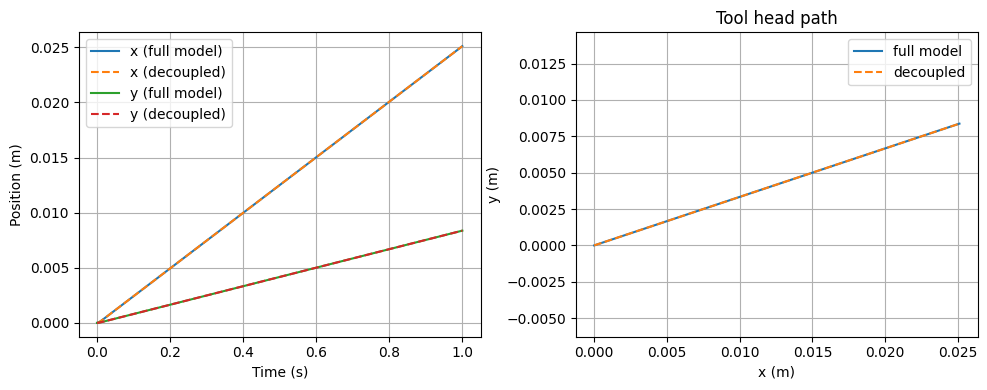

max error x: 2.6749671575010403e-10
max error y: 9.682682433620471e-11


In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(t, pos_x, label='x (full model)')
plt.plot(t, dec_x, '--', label='x (decoupled)')
plt.plot(t, pos_y, label='y (full model)')
plt.plot(t, dec_y, '--', label='y (decoupled)')
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(pos_x, pos_y, label='full model')
plt.plot(dec_x, dec_y, '--', label='decoupled')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Tool head path')
plt.axis('equal')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

print('max error x:', np.max(np.abs(pos_x - dec_x)))
print('max error y:', np.max(np.abs(pos_y - dec_y)))

In [15]:
from scipy.interpolate import make_interp_spline

def u_ref_from_target_sp(x, y, speed, dt=1e-3):
    """Feedforward motor voltages to draw the path through the points (x, y) [m]
    with the nozzle moving at `speed` [m/s]. The result is sampled every dt [s].

    Returns u_ref (2, N), ref_state (6, N), t (N,) and derivs (2, 4, N), where
    derivs[0] = [x, x_dot, x_dot_dot, x_dot_dot_dot] and derivs[1] the same for y.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)

    # time at each point from the path length at constant speed; drop repeated points
    s = np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    s, iu = np.unique(s, return_index=True)
    knots = s / speed

    # quintic spline through the points, differentiated three times
    spl = make_interp_spline(knots, np.array([x[iu], y[iu]]).T, k=5)
    t = np.arange(0, knots[-1], dt)
    derivs = np.array([spl.derivative(k)(t).T if k else spl(t).T for k in range(4)])
    (x, y), (x_dot, y_dot), (x_dot_dot, y_dot_dot), (x_dot_dot_dot, y_dot_dot_dot) = derivs

    theta_l_ref = (x+y)/r_m
    theta_r_ref = (x-y)/r_m

    theta_l_dot_ref = (x_dot+y_dot)/r_m
    theta_r_dot_ref = (x_dot-y_dot)/r_m

    theta_l_dot_dot_ref = (x_dot_dot+y_dot_dot)/r_m
    theta_r_dot_dot_ref = (x_dot_dot-y_dot_dot)/r_m

    theta_l_dot_dot_dot_ref = (x_dot_dot_dot+y_dot_dot_dot)/r_m
    theta_r_dot_dot_dot_ref = (x_dot_dot_dot-y_dot_dot_dot)/r_m

    i_l = (J*theta_l_dot_dot_ref + a*theta_l_dot_ref + b*theta_r_dot_ref)/K_m
    i_r = (J*theta_r_dot_dot_ref + b*theta_l_dot_ref + a*theta_r_dot_ref)/K_m

    i_l_dot = (J*theta_l_dot_dot_dot_ref + a*theta_l_dot_dot_ref + b*theta_r_dot_dot_ref)/K_m
    i_r_dot = (J*theta_r_dot_dot_dot_ref + b*theta_l_dot_dot_ref + a*theta_r_dot_dot_ref)/K_m

    # dx3 = (u_ml - R_m * x3 - K_m * x2) / L_m  ->  u = L_m * i_dot + R_m * i + K_m * theta_dot
    u_l = L_m*i_l_dot + R_m*i_l + K_m*theta_l_dot_ref
    u_r = L_m*i_r_dot + R_m*i_r + K_m*theta_r_dot_ref

    u_ref = np.array([u_l, u_r])

    # state order matches f_ref: [theta_l, theta_l_dot, i_l, theta_r, theta_r_dot, i_r], shape (6, N)
    ref_state = np.array([theta_l_ref, theta_l_dot_ref, i_l, theta_r_ref, theta_r_dot_ref, i_r])

    return u_ref, ref_state, t, derivs


In [16]:
T = 1
W = 2*pi/T

x_c = 20.0
y_c = 20.0
A = 2
B = 1
t = np.linspace(0,T,1000)

x = x_c + A*np.cos(W*t)
y = y_c + B*np.sin(W*t)

u_ref, ref_state, t, derivs = u_ref_from_target_sp(x, y, speed=0.1, dt=T/1000)
x, y = derivs[0]
T = t[-1]


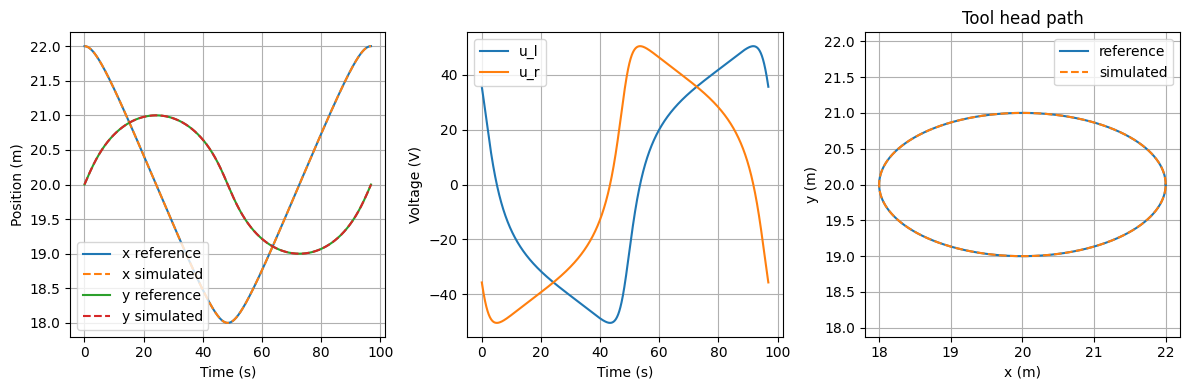

In [17]:
def f_ref(t_now, s):
    u_l_now = np.interp(t_now, t, u_ref[0])
    u_r_now = np.interp(t_now, t, u_ref[1])

    x1 = s[0]
    x2 = s[1]
    x3 = s[2]
    x4 = s[3]
    x5 = s[4]
    x6 = s[5]

    dx1 = x2
    dx2 = (K_m * x3 - a * x2 - b * x5) / J
    dx3 = (u_l_now - R_m * x3 - K_m * x2) / L_m
    dx4 = x5
    dx5 = (K_m * x6 - b * x2 - a * x5) / J
    dx6 = (u_r_now - R_m * x6 - K_m * x5) / L_m

    return [dx1, dx2, dx3, dx4, dx5, dx6]

s0_ref = ref_state[:, 0]   # initial state on the reference trajectory

sol_ref = solve_ivp(f_ref, (0, T), s0_ref, t_eval=t)

t_sim = sol_ref.t
theta_l_sim = sol_ref.y[0]
theta_r_sim = sol_ref.y[3]

x_sim = r_m * (theta_l_sim + theta_r_sim) / 2
y_sim = r_m * (theta_l_sim - theta_r_sim) / 2


plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(t, x, label='x reference')
plt.plot(t_sim, x_sim, '--', label='x simulated')
plt.plot(t, y, label='y reference')
plt.plot(t_sim, y_sim, '--', label='y simulated')
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.legend()
plt.grid()

plt.subplot(1, 3, 2)
plt.plot(t, u_ref[0], label='u_l')
plt.plot(t, u_ref[1], label='u_r')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.legend()
plt.grid()

plt.subplot(1, 3, 3)
plt.plot(x, y, label='reference')
plt.plot(x_sim, y_sim, '--', label='simulated')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Tool head path')
plt.axis('equal')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## TU Delft logo
Extract the outline of the logo, fit a quintic interpolating spline through it, differentiate it three times ($\dot x, \ddot x, \dddot x$, same for $y$) and feed the result to `u_ref_from_target_sp`.

number of contours: 10


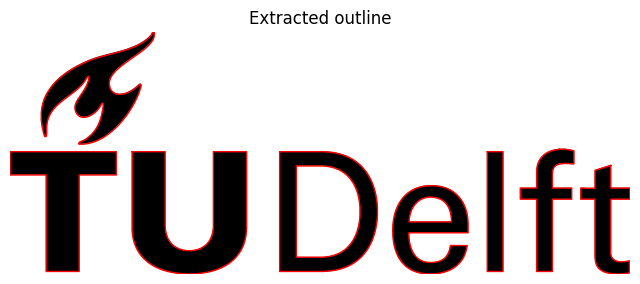

In [18]:
import cv2
from scipy.interpolate import make_interp_spline

# composite on white background (png has alpha), then binarise
img = cv2.imread('images/tudelft.png', cv2.IMREAD_UNCHANGED).astype(float)
if img.shape[2] == 4:
    alpha = img[:, :, 3:] / 255
    img = img[:, :, :3] * alpha + 255 * (1 - alpha)
gray = img.mean(axis=2)
mask = (gray < 250).astype(np.uint8)

# outer contours and holes (D, e, l, ... have holes)
contours, _ = cv2.findContours(mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
print('number of contours:', len(contours))

plt.figure(figsize=(8, 4))
plt.imshow(mask, cmap='gray_r')
for c in contours:
    plt.plot(c[:, 0, 0], c[:, 0, 1], 'r', lw=1)
plt.title('Extracted outline')
plt.axis('off')
plt.show()

In [19]:
num_points = 120    # control points per contour

ctrl = []
for c in contours:
    px = c[:, 0, 0].astype(float)
    py = -c[:, 0, 1].astype(float)
    idx = np.unique(np.round(np.linspace(0, len(px) - 1, num_points)).astype(int))
    ctrl.append(np.array([px[idx], py[idx]]))
ctrl = np.hstack(ctrl)

print_area = 0.29
draw_size = 0.20
margin = (print_area - draw_size) / 2
px_to_m = draw_size / max(mask.shape)

ctrl = ctrl - ctrl.min(axis=1, keepdims=True)
ctrl = margin + px_to_m * ctrl

# arc length parametrisation, resampled to uniform spacing
seg = np.linalg.norm(np.diff(ctrl, axis=1), axis=0)
s = np.concatenate([[0], np.cumsum(seg)])
s, iu = np.unique(s, return_index=True)
s_q = np.linspace(0, s[-1], int(np.ceil(s[-1] / np.median(np.diff(s)))) + 1)
pts = np.array([np.interp(s_q, s, ctrl[0, iu]), np.interp(s_q, s, ctrl[1, iu])])

In [20]:
v_avg = 0.01                      # nozzle speed (m/s)

u_ref_tud, ref_state_tud, t_tud, derivs_tud = u_ref_from_target_sp(pts[0], pts[1], speed=0.5)
T_tud = t_tud[-1]

x_tud, y_tud = derivs_tud[0]
xd_tud, yd_tud = derivs_tud[1]
xdd_tud, ydd_tud = derivs_tud[2]
xddd_tud, yddd_tud = derivs_tud[3]
print(f'T = {T_tud:.1f} s, {len(t_tud)} samples')

T = 3.6 s, 3576 samples


In [21]:
def f_ref_tud(t_now, s):
    u_l_now = np.interp(t_now, t_tud, u_ref_tud[0])
    u_r_now = np.interp(t_now, t_tud, u_ref_tud[1])
    return [s[1],
            (K_m * s[2] - a * s[1] - b * s[4]) / J,
            (u_l_now - R_m * s[2] - K_m * s[1]) / L_m,
            s[4],
            (K_m * s[5] - b * s[1] - a * s[4]) / J,
            (u_r_now - R_m * s[5] - K_m * s[4]) / L_m]

# electrical dynamics are fast (L/R ~ 1e-4 s), so use a stiff solver
sol_tud = solve_ivp(f_ref_tud, (0, T_tud), ref_state_tud[:, 0], t_eval=t_tud,
                    method='LSODA', rtol=1e-8, atol=1e-10)

x_sim_tud = r_m * (sol_tud.y[0] + sol_tud.y[3]) / 2
y_sim_tud = r_m * (sol_tud.y[0] - sol_tud.y[3]) / 2

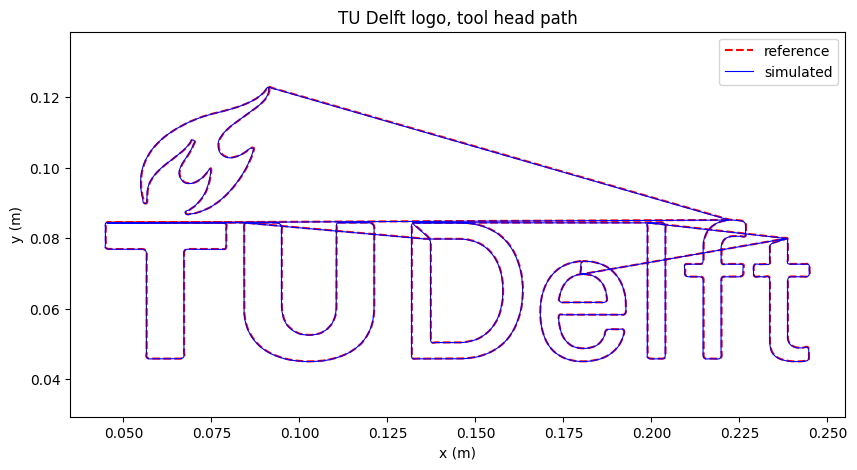

max position error (mm): 0.22031138688050786


In [22]:
plt.figure(figsize=(10, 5))
plt.plot(x_tud, y_tud, 'r--', label='reference')
plt.plot(x_sim_tud, y_sim_tud, 'b-', lw=0.8, label='simulated')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('TU Delft logo, tool head path')
plt.axis('equal')
plt.legend()
plt.grid# The constants were blindly generated from my notes so I can run the simulation, they need to be checked and probably changed (density seems a bit too high for plastic :) 
()
plt.show()

print('max position error (mm):', 1e3 * np.max(np.hypot(x_sim_tud - x_tud, y_sim_tud - y_tud)))

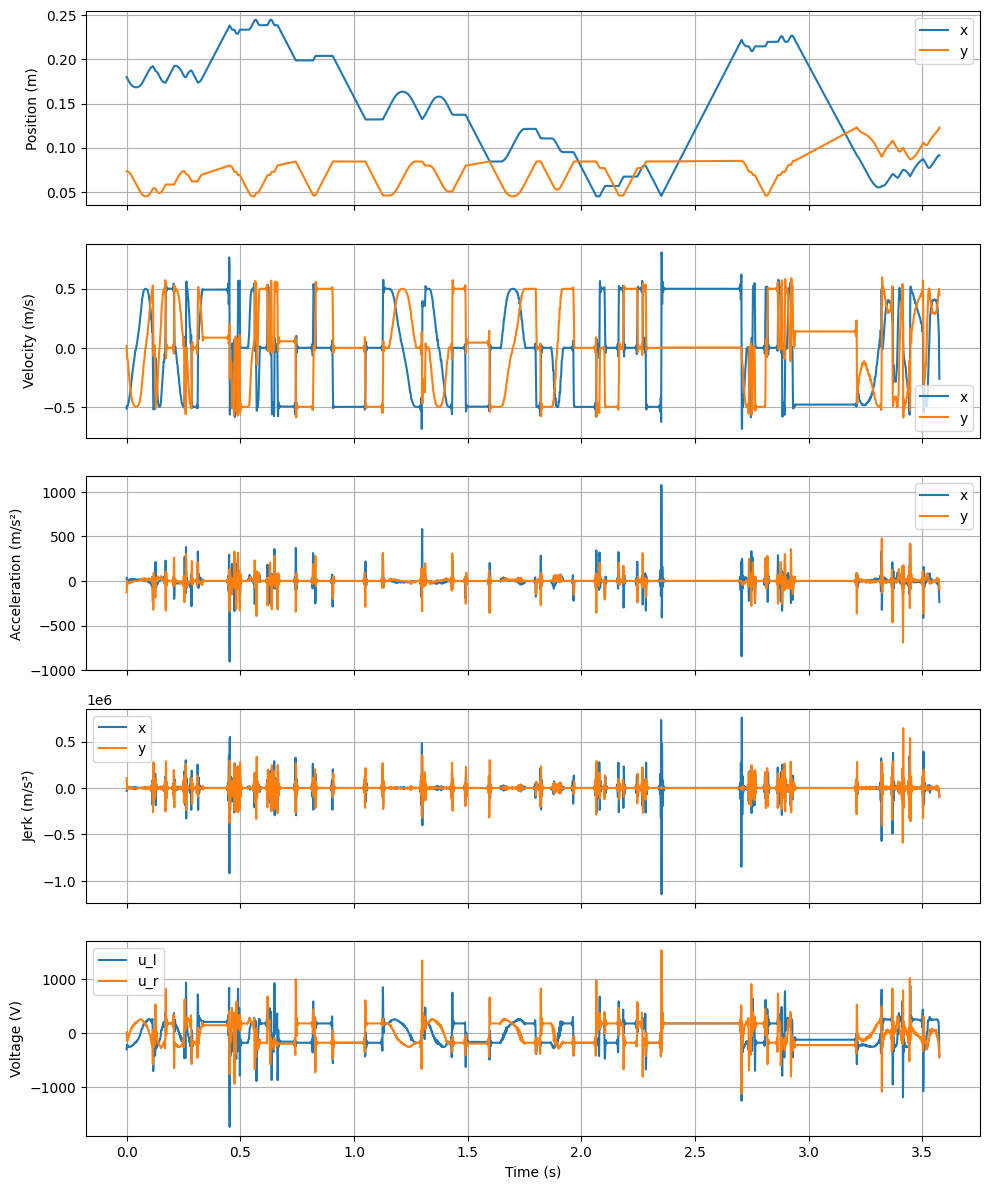

In [23]:
fig, ax = plt.subplots(5, 1, figsize=(10, 12), sharex=True)
for axi, (xv, yv, lab) in zip(ax, [(x_tud, y_tud, 'Position (m)'),
                                   (xd_tud, yd_tud, 'Velocity (m/s)'),
                                   (xdd_tud, ydd_tud, 'Acceleration (m/s²)'),
                                   (xddd_tud, yddd_tud, 'Jerk (m/s³)')]):
    axi.plot(t_tud, xv, label='x')
    axi.plot(t_tud, yv, label='y')
    axi.set_ylabel(lab)
    axi.legend()
    axi.grid()
ax[4].plot(t_tud, u_ref_tud[0], label='u_l')
ax[4].plot(t_tud, u_ref_tud[1], label='u_r')
ax[4].set_ylabel('Voltage (V)')
ax[4].set_xlabel('Time (s)')
ax[4].legend()
ax[4].grid()
plt.tight_layout()
plt.show()

## Nozzle Modelling
The nozzle heater is an RLC circuit (inductor $L_n$, capacitor $C_n$, heater resistance $R_n$) driven by the voltage $u_n$. The heater dissipates $V_c^2/R_n$ as heat in the nozzle, which has thermal capacitance $C_{t,n}$. The heat loss to the environment (including the filament) is lumped into one thermal resistance $R_{t,n}$ with respect to the environment temperature $T_e$.

Electrical part (inductor current $i_n$, capacitor voltage $V_c$):
$$L_n \dot i_n = u_n - V_c, \qquad C_n \dot V_c = i_n - \frac{V_c}{R_n}$$

Thermal part (energy balance on the nozzle, $C_{t,n}\dot T_n = W_{in} - W_{out}$):
$$C_{t,n}\dot T_n = \frac{V_c^2}{R_n} - \frac{T_n - T_e}{R_{t,n}}$$

With $\boldsymbol x_n = [T_n,\ i_n,\ V_c]^\top$ this gives $\dot{\boldsymbol x}_n = f_n(\boldsymbol x_n, u_n)$:
$$\begin{bmatrix} \dot T_n \\ \dot i_n \\ \dot V_c \end{bmatrix} = \begin{bmatrix} \dfrac{1}{C_{t,n}}\left(\dfrac{V_c^2}{R_n} - \dfrac{T_n - T_e}{R_{t,n}}\right) \\ \dfrac{1}{L_n}\left(u_n - V_c\right) \\ \dfrac{1}{C_n}\left(i_n - \dfrac{V_c}{R_n}\right) \end{bmatrix}$$

The electrical subsystem is linear and does not depend on $T_n$; the only nonlinearity is the $V_c^2$ heating term.

In [24]:
# PLACEHOLDER values, to be checked/replaced
L_n   = 1e-3   # heater circuit inductance (H)
C_n   = 1e-4   # heater circuit capacitance (F)
R_n   = 10.0   # heater resistance (Ohm)
C_tn  = 5.0    # nozzle thermal capacitance (J/K)
R_tn  = 20.0   # thermal resistance to environment (K/W)
T_e   = 20.0   # environment temperature (deg C)


def f_n(t, x, u_n):
    T_n = x[0]
    i_n = x[1]
    V_c = x[2]

    dT_n = (V_c**2 / R_n - (T_n - T_e) / R_tn) / C_tn
    di_n = (u_n - V_c) / L_n
    dV_c = (i_n - V_c / R_n) / C_n

    return [dT_n, di_n, dV_c]

In [25]:
U_n   = 12.0   # sine amplitude (V), chosen
f_n_hz = 5.0   # sine frequency (Hz), chosen

def u_n_sine(t):
    return U_n * np.sin(2 * pi * f_n_hz * t)

t_n = np.linspace(0, 1, 1000)
xn0 = [T_e, 0, 0]   # nozzle at ambient, circuit at rest

# electrical dynamics are fast, so use a stiff solver
sol_n = solve_ivp(lambda t, x: f_n(t, x, u_n_sine(t)), (0, 1), xn0, t_eval=t_n,
                  method='LSODA', rtol=1e-8, atol=1e-10)

T_n_sim, i_n_sim, V_c_sim = sol_n.y

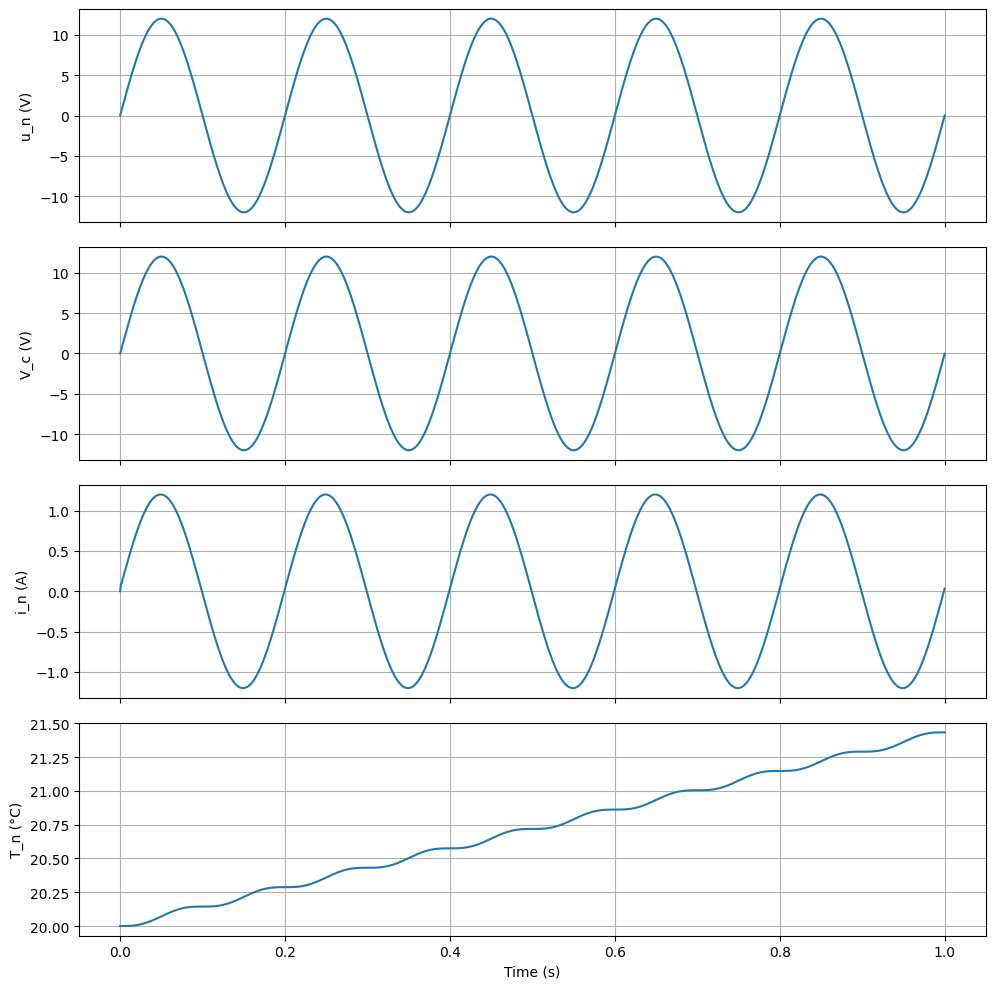

In [26]:
fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True)

ax[0].plot(t_n, u_n_sine(t_n))
ax[0].set_ylabel('u_n (V)')

ax[1].plot(t_n, V_c_sim)
ax[1].set_ylabel('V_c (V)')

ax[2].plot(t_n, i_n_sim)
ax[2].set_ylabel('i_n (A)')

ax[3].plot(t_n, T_n_sim)
ax[3].set_ylabel('T_n (°C)')
ax[3].set_xlabel('Time (s)')

for a_ in ax:
    a_.grid()

plt.tight_layout()
plt.show()

## Modelling Material Cooling

$$\partial_t T = \kappa'\,\partial_{xx}T - \beta\,(T - T_e), \qquad \kappa' = \frac{\kappa}{\rho C},\quad \beta = \frac{h\,P}{\rho C\,A}$$


$$
\begin{aligned}
&T(0,t) = 100^{\circ}\mathrm{C} &\quad& \text{(heater)} \\
&\partial_x T(L,t) = 0 &\quad& \text{(insulated end)} \\
&T(x,0) = 100^{\circ}\mathrm{C} &\quad& \text{(starts hot everywhere)}
\end{aligned}
$$


### Constants

| Quantity | Symbol | Value | Unit |
|---|---|---|---|
| Density | $\rho$ | 1000 | kg/m³ |
| Specific heat | $C$ | 1500 | J/(kg·K) |
| Thermal conductivity | $\kappa$ | 0.2 | W/(m·K) |
| Heat-transfer coefficient (still air) | $h$ | 10 | W/(m²·K) |
| Bar length | $L$ | 0.1 | m |
| Bar side (square cross-section) | $a$ | 0.01 | m |
| Cross-section area | $A = a^2$ | $1.0 \times 10^{-4}$ | m² |
| Perimeter | $P = 4a$ | 0.04 | m |
| Heater temperature | $T_H$ | 100 | °C |
| Initial temperature | $T_0$ | 100 | °C |
| Ambient temperature | $T_e$ | 20 | °C |

### Derived quantities

| Quantity | Formula | Value | Unit |
|---|---|---|---|
| Thermal diffusivity | $\kappa' = \kappa / (\rho C)$ | $1.33 \times 10^{-7}$ | m²/s |
| Side-cooling rate | $\beta = h P / (\rho C A)$ | $2.67 \times 10^{-3}$ | 1/s |
| Fin parameter | $m = \sqrt{\beta / \kappa'}$ | 141 | 1/m |
| Heat reach | $1/m$ | 7.1 | mm |
| Slowest time constant | $\tau_1 = 1 / \left(\kappa' (\pi^2 / 4L^2 + m^2)\right)$ | ≈ 370 | s |
| Steady heater power | $\kappa A (T_H - T_e)\, m \tanh(mL)$ | ≈ 0.23 | W |
| Max stable time step (explicit Euler) | $\Delta t \le \Delta x^2 / (2\kappa')$ | 0.037 for $\Delta x = 0.1$ mm | s |






In [ ]:
#Assuming for a fixed printed length L, the material is at T=T_nozzle. 
# The printing bed and air both have the same heat transfer constants,the nozzle temperature is constant.

L = 1
a = 0.002
RHO, C, KAPPA = 1200, 1500,0.2
H_AIR = 20.0
H_BED = 100.0

T_HOT, T_ENV, T_BED = 60.0, 20.0, 40

ALPHA = KAPPA/(RHO*C)
BETA = 3*H_AIR/(RHO*C*a)
GAMMA = H_BED/(RHO*C*a)

L0 = 0.01
N = 10

V = 0.05 #m/s

L_final = 1.0

dx = L0/N

def rhs(t,T):

    dTdt = np.zeros_like(T)

    if len(T) >= 3:
        dTdt[1:-1] = (ALPHA*(T[2:]-2*T[1:-1]+T[:-2])/dx**2 + BETA*(T_ENV-T[1:-1]) + GAMMA*(T_BED-T[1:-1]))

    if len(T) >= 2:
        dTdt[0] = ALPHA*2*(T[1] - T[0])/dx**2 + BETA*(T_ENV - T[0]) + GAMMA*(T_BED - T[0])   # start end: insulated

    
    if t<20: # Assuming at t=20s, the nozzle is lifted
        dTdt[-1] = 0.0                                                    # tip: held at T_HOT by the nozzle
    else:
        dTdt[-1] = ALPHA*2*(T[-2] - T[-1])/dx**2 + BETA*(T_ENV - T[-1]) + GAMMA*(T_BED - T[-1])  # start end: insulated

    return dTdt


N_TARGET = int(round((L_final-L0)/dx)) + 1     # stop once the filament has reached the final length L
DT_SEG = 0.02                       # time per segment [s]
n_add = int(round(V*DT_SEG/dx))     # points the nozzle prints per segment

T = np.array([T_HOT])               # first printed point
t0 = 0.0
t_hist = [t0]                       # timestamps
T_hist = [T.copy()]                 # state history (list of arrays, lengths differ)


iters = round((L_final-L0)/(V*DT_SEG))
print(f"ITERS: {iters}")

while t0<100 or np.all(np.abs(T - T[0]) >= 0.5):
    t1 = t0 + DT_SEG
    n = min(n_add, N_TARGET - len(T))
    T = np.concatenate([T, np.full(n, T_HOT)])

    sol = solve_ivp(rhs,(t0,t1),T,method="RK45",t_eval=[t1])

    T = sol.y[:, -1]
    t0 = t1
    t_hist.append(t0)
    T_hist.append(T.copy())

print(len(T), t0)
print(T.shape)


ITERS: 990
991 100.01999999999724
(991,)
[32.8237381  32.82376263 32.82383514 32.82395243 32.82410967 32.82430098
 32.82452007 32.82476084 32.82501783 32.82528645 32.82556309 32.82584508
 32.82613051 32.82641813 32.82670712 32.82699699 32.82728745 32.82757834
 32.82786958 32.82816111 32.82845292 32.828745   32.82903735 32.82932995
 32.82962282 32.82991595 32.83020934 32.83050299 32.8307969  32.83109107
 32.8313855  32.8316802  32.83197516 32.83227037 32.83256586 32.8328616
 32.83315761 32.83345388 32.83375042 32.83404721 32.83434428 32.8346416
 32.83493919 32.83523705 32.83553517 32.83583356 32.83613221 32.83643112
 32.8367303  32.83702975 32.83732947 32.83762945 32.8379297  32.83823021
 32.83853099 32.83883204 32.83913336 32.83943495 32.8397368  32.84003892
 32.84034131 32.84064397 32.8409469  32.8412501  32.84155357 32.8418573
 32.84216131 32.84246559 32.84277014 32.84307496 32.84338005 32.84368541
 32.84399104 32.84429695 32.84460312 32.84490957 32.8452163  32.84552329
 32.84583056 

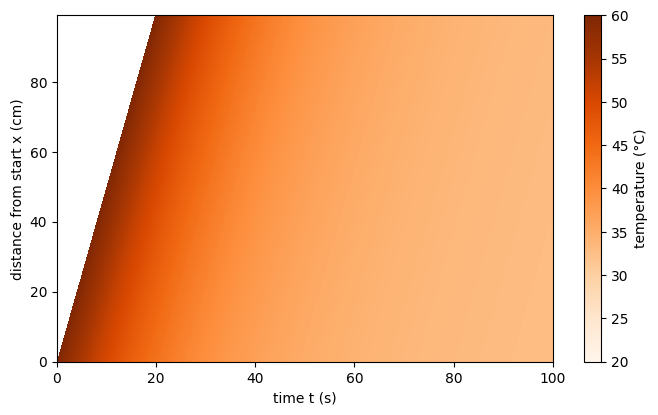

In [57]:

n_max = max(len(T_k) for T_k in T_hist)
hist = np.full((n_max, len(T_hist)), np.nan)
for k, T_k in enumerate(T_hist):
    hist[:len(T_k), k] = T_k

# 2) heatmap: rows = position, columns = time
fig, ax = plt.subplots(figsize=(8, 4.5))
m = ax.pcolormesh(t_hist, np.arange(n_max) * dx * 100, hist,
                  cmap="Oranges", vmin=T_ENV, vmax=T_HOT, shading="auto")
fig.colorbar(m, ax=ax, label="temperature (°C)")
ax.set_xlabel("time t (s)")
ax.set_ylabel("distance from start x (cm)")
plt.show()


## Q2.1 Finite State Machines

In [ ]:
from enum import Enum
import pandas as pd
#ADD current directory to python path



class PrintingStates(Enum):
    """
    Defining enums for printing States
    """
    IDLE = 0
    IN_PROGRESS = 1
    PAUSED = 2
    ABORTED = 3
    FAILED = 4
    COMPLETED = 5

class FilamentReplacementStates(Enum):
    """
    Defining enums for Filament Replacement States
    """
    IDLE = 0
    MOVING_TO_WIPING_LOCATION = 1
    WIPING = 2
    NOZZLE_COOLING = 3
    LOADING_FILAMENT = 4
    NOZZLE_HEATING = 5







In [88]:
DONT_CARE = "X"
STATE_COLS = ["printing_state", "filament_change_state", "retries_left"]
INPUT_COLS = ["external_input", "system_feedback"]
OUTPUT_COLS = ["output_printing_state","output_filament_change_state","output_message","output_retries_left"]

# blank cells become "" (not NaN), then remove leading/trailing whitespace from every cell

transition_table = pd.read_csv(
    "state_transition_tables/filament_change_state_transition_table.csv",
    dtype=str, keep_default_na=False,  # keep "null", "X" and blanks as literal text
)

transition_table = transition_table.fillna("").apply(lambda col: col.str.strip())

def cell_matches(table_value, actual_value):
    # "X" matches anything, a blank cell only matches when no input was given
    if table_value == DONT_CARE:
        return True
    return table_value == actual_value

def resolve_output(table_value, current_value):
    # "X" and blank output cells keep the current value
    return current_value if table_value in (DONT_CARE, "") else table_value

def state_update(current_state, system_input):
    print(f"CURRENT STATE: {current_state}")
    row_to_check = {
        "printing_state": current_state["printing_state"],
        "filament_change_state": current_state["filament_change_state"],
        "retries_left": current_state["retries_left"],
        "external_input": system_input["external_input"],
        "system_feedback": system_input["system_feedback"]
    }
    # compare everything as stripped strings, None becomes ""
    row_to_check = {k: "" if v is None else str(v).strip() for k, v in row_to_check.items()}

    # first row whose input columns all match wins
    def generate_output(input_row, table_row):
        for col in INPUT_COLS+STATE_COLS:

            if table_row[col] == DONT_CARE:
                continue
            elif table_row[col] != input_row[col]:
                return False, {}


        for col in OUTPUT_COLS:
            if table_row[col] == DONT_CARE:
                table_row[col] = input_row[col.removeprefix("output_")]
        output_state = {col: table_row[col] for col in OUTPUT_COLS}
        return True, output_state

    print(row_to_check)
    for _, row in transition_table.iterrows():
        row_match,output = generate_output(row_to_check,row)
        if row_match:
            next_state = {col:output[f"output_{col}"] for col in STATE_COLS}
            message = output["output_message"]

            return next_state,message
                

    return current_state, "NO MATCHING TRANSITION"



In [89]:
current_state = {
    "printing_state": PrintingStates.IN_PROGRESS.name,
    "filament_change_state": FilamentReplacementStates.IDLE.name,
    "retries_left": 3
}

# walk through a filament change where every step succeeds
inputs = [
    {"external_input": "C", "system_feedback": None},
]
for system_input in inputs:
    current_state, msg = state_update(current_state, system_input)
    print(f"OUTPUT STATE: {current_state}")
    print(f"MESSAGE: {msg}")


CURRENT STATE: {'printing_state': 'IN_PROGRESS', 'filament_change_state': 'IDLE', 'retries_left': 3}
{'printing_state': 'IN_PROGRESS', 'filament_change_state': 'IDLE', 'retries_left': '3', 'external_input': 'C', 'system_feedback': ''}
OUTPUT STATE: {'printing_state': 'PAUSED', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}
MESSAGE: "FILAMENT CHANGE IN PROGRESS"


In [90]:
import io
import contextlib

test_cases = pd.read_csv("state_transition_tables/test_cases.csv", dtype=str, keep_default_na=False)

results = []
for _, case in test_cases.iterrows():
    state = {
        "printing_state": case["printing_state"],
        "filament_change_state": case["filament_change_state"],
        "retries_left": case["retries_left"],
    }
    system_input = {
        "external_input": case["external_input"] or None,
        "system_feedback": case["system_feedback"] or None,
    }
    # silence the debug prints inside state_update
    with contextlib.redirect_stdout(io.StringIO()):
        next_state, msg = state_update(state, system_input)

    handled = msg != "NO MATCHING TRANSITION"
    results.append({
        "case": case["case"],
        "description": case["description"],
        "realistic": case["realistic"],
        "handled": handled,
        "next_state": next_state if handled else "",
        "message": msg,
    })

results = pd.DataFrame(results)
pd.set_option("display.max_colwidth", None)
display(results)

missing = results[(results["realistic"] == "yes") & ~results["handled"]]
print(f"\n{len(missing)} realistic case(s) have NO transition in the table:")
for _, r in missing.iterrows():
    print(f"  case {r['case']}: {r['description']}")

,case,description,realistic,handled,next_state,message
0,1,Start filament change (C) while printer idle,yes,True,"{'printing_state': 'IDLE', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}","""FILAMENT CHANGE IN PROGRESS"""
1,2,Filament runout (F) while printer idle,yes,True,"{'printing_state': 'IDLE', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}","""FILAMENT CHANGE IN PROGRESS"""
2,3,Filament change (C) requested mid-print,yes,True,"{'printing_state': 'PAUSED', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}","""FILAMENT CHANGE IN PROGRESS"""
3,4,Filament runout (F) mid-print,yes,True,"{'printing_state': 'PAUSED', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}","""FILAMENT CHANGE IN PROGRESS"""
4,5,Filament change (C) while print is paused,yes,True,"{'printing_state': 'PAUSED', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}","""FILAMENT CHANGE IN PROGRESS"""
5,6,Filament runout (F) while print is paused,yes,True,"{'printing_state': 'PAUSED', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '3'}","""FILAMENT CHANGE IN PROGRESS"""
6,11,Moving to wiping location succeeds first try,yes,True,"{'printing_state': 'IDLE', 'filament_change_state': 'WIPING', 'retries_left': '3'}","""MOVING_TO_WIPING_LOCATION_SUCCESSFUL"""
7,12,Moving to wiping location fails first try,yes,True,"{'printing_state': 'IDLE', 'filament_change_state': 'MOVING_TO_WIPING_LOCATION', 'retries_left': '2'}","""MOVING_TO_WIPING_LOCATION_FAILURE. TRYING AGAIN"""
8,13,Moving to wiping location fails with no retries left,yes,True,"{'printing_state': 'IDLE', 'filament_change_state': 'IDLE', 'retries_left': '3'}",""" FILAMENT CHANGE PROCESS FAILED. INITIATE FILAMENT CHANGE AGAIN"""
9,14,Moving to wiping location succeeds after a retry,yes,True,"{'printing_state': 'IDLE', 'filament_change_state': 'WIPING', 'retries_left': '3'}","""MOVING_TO_WIPING_LOCATION_SUCCESSFUL"""



0 realistic case(s) have NO transition in the table:
